**PÓS-GRADUAÇÃO · DATA SCIENCE & BIG DATA APLICADOS NA INDÚSTRIA**

# Aula 06 · Exercício 01
## Monitoramento da temperatura de uma máquina

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Python para Data Science |
| **Professor** | Me. Daniel Vieira |
| **Data** | 13/11/2026 |

---

**Tema:** organização dos dados com Pandas e gráfico de linhas com Matplotlib.


In [1]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
# 2. CRIAÇÃO DO DATAFRAME
dados = {
    "tempo": ["08:00", "09:00", "10:00", "11:00", "12:00",
              "13:00", "14:00", "15:00", "16:00", "17:00"],
    "temperatura": [25, 28, 32, 35, 38, 42, 45, 41, 37, 33]
}
df = pd.DataFrame(dados)
display(df)


,tempo,temperatura
0,08:00,25
1,09:00,28
2,10:00,32
3,11:00,35
4,12:00,38
5,13:00,42
6,14:00,45
7,15:00,41
8,16:00,37
9,17:00,33


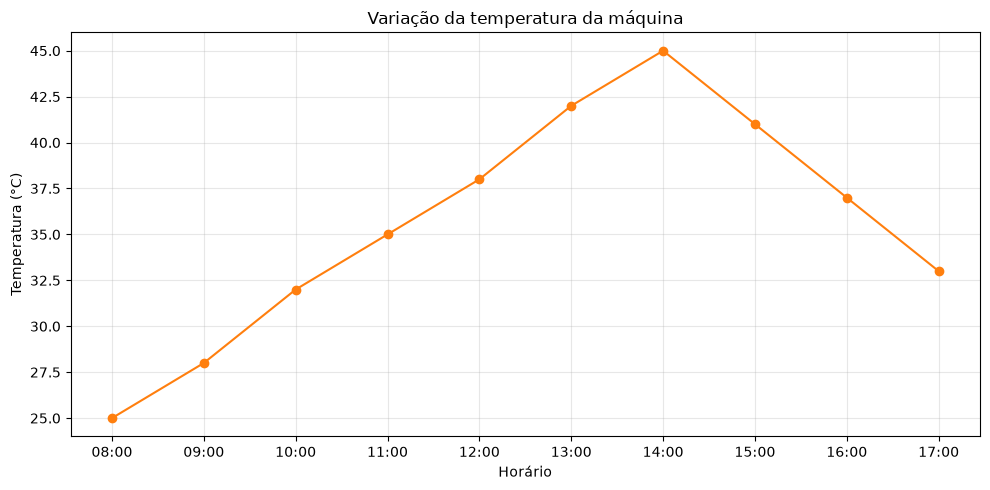

In [3]:
# 3. GRÁFICO DE LINHAS
plt.figure(figsize=(10, 5))
plt.plot(df["tempo"], df["temperatura"], marker="o", color="tab:orange")
plt.title("Variação da temperatura da máquina")
plt.xlabel("Horário")
plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Questões para análise


### a) Em qual horário foi registrada a maior temperatura?


In [4]:
temperatura_maxima = df["temperatura"].max()
display(df.loc[df["temperatura"] == temperatura_maxima, ["tempo", "temperatura"]])


,tempo,temperatura
6,14:00,45


A maior temperatura foi registrada às **14:00**, com **45 °C**.


### b) Qual foi a menor temperatura registrada?


In [5]:
temperatura_minima = df["temperatura"].min()
print(f"Menor temperatura: {temperatura_minima} °C")


Menor temperatura: 25 °C


A menor temperatura registrada foi de **25 °C**, às 08:00.


### c) Em qual intervalo ocorreu a maior elevação de temperatura?


In [6]:
# diff() calcula a diferença entre uma leitura e a anterior.
# shift() coloca o horário anterior ao lado do horário atual.
df["variacao_temperatura"] = df["temperatura"].diff()
intervalos = pd.DataFrame({
    "horario_inicial": df["tempo"].shift(1),
    "horario_final": df["tempo"],
    "elevacao_c": df["variacao_temperatura"]
}).dropna()
maior_elevacao = intervalos["elevacao_c"].max()
display(intervalos)
print("Intervalos com a maior elevação:")
display(intervalos.loc[intervalos["elevacao_c"] == maior_elevacao])


,horario_inicial,horario_final,elevacao_c
1,08:00,09:00,3.0
2,09:00,10:00,4.0
3,10:00,11:00,3.0
4,11:00,12:00,3.0
5,12:00,13:00,4.0
6,13:00,14:00,3.0
7,14:00,15:00,-4.0
8,15:00,16:00,-4.0
9,16:00,17:00,-4.0


Intervalos com a maior elevação:


,horario_inicial,horario_final,elevacao_c
2,09:00,10:00,4.0
5,12:00,13:00,4.0


Houve empate: a maior elevação foi de **4 °C**, tanto de **09:00 a 10:00** quanto de **12:00 a 13:00**. Como as leituras têm uma hora de intervalo, isso corresponde a uma elevação média de 4 °C por hora nesses dois intervalos.


### d) Como calcular a temperatura média utilizando df["temperatura"].mean()?


In [7]:
temperatura_media = df["temperatura"].mean()
print(f"Temperatura média: {temperatura_media:.1f} °C")


Temperatura média: 35.6 °C


Usamos `df["temperatura"].mean()`. A média das dez leituras foi de **35,6 °C**.


## Conclusão

A temperatura aumentou de 25 °C às 08:00 até 45 °C às 14:00. Depois, diminuiu até 33 °C às 17:00. O gráfico permite acompanhar essa mudança, mas o enunciado não informa limites operacionais para avaliar se as temperaturas são adequadas à máquina.
